In [ ]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import pandas as pd
from src.finguard.ml.features import build_features, NUMERIC_FEATURES, CATEGORICAL_FEATURES


In [3]:
train_df = pd.read_csv("data/raw/fraudTrain.csv")
test_df = pd.read_csv("data/raw/fraudTest.csv")

In [7]:
train_df['trans_date_trans_time'] = pd.to_datetime(train_df['trans_date_trans_time'])
test_df['trans_date_trans_time'] = pd.to_datetime(test_df['trans_date_trans_time'])

In [8]:

train_df["split"] = "train"
test_df["split"] = "test"

# build features on both together, so test cards keep their history from train
all_fe = build_features(pd.concat([train_df, test_df], ignore_index=True))

train_fe = all_fe[all_fe["split"] == "train"].copy()
test_fe = all_fe[all_fe["split"] == "test"].copy()

# make sure train and test use the same category codes
cats = sorted(train_fe["category"].unique())
train_fe["category"] = pd.Categorical(train_fe["category"], categories=cats)
test_fe["category"] = pd.Categorical(test_fe["category"], categories=cats)

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
X_train, y_train = train_fe[FEATURES], train_fe["is_fraud"]
X_test, y_test = test_fe[FEATURES], test_fe["is_fraud"]

print(X_train.shape, X_test.shape)
print("fraud rate train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))
print("test rows with no card history:", (test_fe["card_txn_count"] == 0).mean())

(1296675, 11) (555719, 11)
fraud rate train: 0.0058 | test: 0.0039
test rows with no card history: 2.8791529532011683e-05


In [9]:
from xgboost import XGBClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             classification_report, confusion_matrix)

# hold out the latest 15% of train (by date) to know when to stop training
cutoff = train_fe["trans_date_trans_time"].quantile(0.85)
fit_mask = train_fe["trans_date_trans_time"] <= cutoff
X_fit, y_fit = X_train[fit_mask], y_train[fit_mask]
X_val, y_val = X_train[~fit_mask], y_train[~fit_mask]

# class weight: how much more to care about each fraud case
spw = (y_fit == 0).sum() / (y_fit == 1).sum()
print("scale_pos_weight:", round(spw, 1))

model = XGBClassifier(
    n_estimators=500, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=spw, tree_method="hist", enable_categorical=True,
    eval_metric="aucpr", early_stopping_rounds=30,
    n_jobs=-1, random_state=42,
)
model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=50)

# evaluate on the untouched test set
proba = model.predict_proba(X_test)[:, 1]
print("\nTest PR-AUC :", round(average_precision_score(y_test, proba), 4),
      "(random guessing =", round(y_test.mean(), 4), ")")
print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 4))

pred = (proba >= 0.5).astype(int)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=3))

scale_pos_weight: 171.9
[0]	validation_0-aucpr:0.51505
[50]	validation_0-aucpr:0.81476
[100]	validation_0-aucpr:0.88458
[150]	validation_0-aucpr:0.91715
[200]	validation_0-aucpr:0.92357
[250]	validation_0-aucpr:0.92748
[300]	validation_0-aucpr:0.92955
[350]	validation_0-aucpr:0.93157
[400]	validation_0-aucpr:0.93257
[450]	validation_0-aucpr:0.93372
[499]	validation_0-aucpr:0.93525

Test PR-AUC : 0.8792 (random guessing = 0.0039 )
Test ROC-AUC: 0.9975
[[552809    765]
 [   346   1799]]
              precision    recall  f1-score   support

           0      0.999     0.999     0.999    553574
           1      0.702     0.839     0.764      2145

    accuracy                          0.998    555719
   macro avg      0.851     0.919     0.882    555719
weighted avg      0.998     0.998     0.998    555719



In [10]:
import numpy as np

val_proba = model.predict_proba(X_val)[:, 1]
amt_val = train_fe.loc[X_val.index, "amt"].values
yv = y_val.values

REVIEW_COST = 10   # ASSUMPTION: $10 of analyst time per flagged transaction

def total_cost(y, p, amt, thr):
    flag = p >= thr
    missed_loss = amt[(y == 1) & ~flag].sum()          # fraud we let through
    review = REVIEW_COST * ((y == 0) & flag).sum()     # false alarms
    return missed_loss + review

thresholds = np.linspace(0.01, 0.99, 99)
costs = [total_cost(yv, val_proba, amt_val, t) for t in thresholds]
best_thr = thresholds[int(np.argmin(costs))]
print("best threshold:", round(best_thr, 2))

# apply to test ONCE
test_proba = model.predict_proba(X_test)[:, 1]
amt_test = test_fe["amt"].values
pred = (test_proba >= best_thr).astype(int)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=3))
print("cost at best threshold:", round(total_cost(y_test.values, test_proba, amt_test, best_thr)))
print("cost at 0.5 threshold :", round(total_cost(y_test.values, test_proba, amt_test, 0.5)))
print("cost if we flag nothing:", round(amt_test[y_test.values == 1].sum()))

best threshold: 0.25
[[551886   1688]
 [   231   1914]]
              precision    recall  f1-score   support

           0      1.000     0.997     0.998    553574
           1      0.531     0.892     0.666      2145

    accuracy                          0.997    555719
   macro avg      0.765     0.945     0.832    555719
weighted avg      0.998     0.997     0.997    555719

cost at best threshold: 88905
cost at 0.5 threshold : 127841
cost if we flag nothing: 1133325


<Axes: title={'center': 'XGBoost feature importance'}>

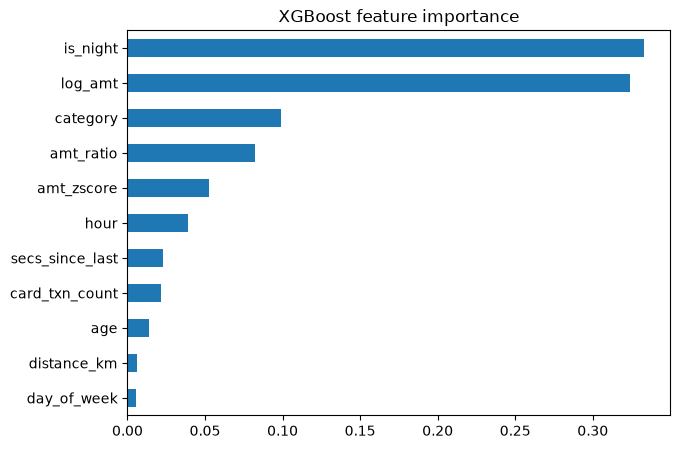

In [11]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 5), title="XGBoost feature importance")

In [12]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score

num_cols = NUMERIC_FEATURES
fill = X_fit[num_cols].median()
Xi_fit = X_fit[num_cols].fillna(fill)
Xi_test = X_test[num_cols].fillna(fill)

iso = IsolationForest(n_estimators=300, random_state=42, n_jobs=-1)
iso.fit(Xi_fit)                                   # note: NO labels used

anomaly_score = -iso.score_samples(Xi_test)       # higher = more unusual
print("IsolationForest test PR-AUC :", round(average_precision_score(y_test, anomaly_score), 4))
print("IsolationForest test ROC-AUC:", round(roc_auc_score(y_test, anomaly_score), 4))
print("(XGBoost PR-AUC was 0.8792, random guess =", round(y_test.mean(), 4), ")")

IsolationForest test PR-AUC : 0.1642
IsolationForest test ROC-AUC: 0.9072
(XGBoost PR-AUC was 0.8792, random guess = 0.0039 )


In [13]:
import pandas as pd
import numpy as np

iso_pct = pd.Series(anomaly_score).rank(pct=True).values     # 1.0 = most anomalous
is_fraud = y_test.values == 1
missed = is_fraud & (test_proba < best_thr)                  # frauds XGBoost let through

print("frauds missed by XGBoost:", missed.sum())
print("median anomaly percentile, all frauds   :", round(np.median(iso_pct[is_fraud]), 3))
print("median anomaly percentile, missed frauds:", round(np.median(iso_pct[missed]), 3))
print("share of missed frauds in top 5% most anomalous:", round((iso_pct[missed] >= 0.95).mean(), 3))
print("share of missed frauds in top 10% most anomalous:", round((iso_pct[missed] >= 0.90).mean(), 3))

frauds missed by XGBoost: 231
median anomaly percentile, all frauds   : 0.989
median anomaly percentile, missed frauds: 0.922
share of missed frauds in top 5% most anomalous: 0.45
share of missed frauds in top 10% most anomalous: 0.55


In [14]:
Xi_val = X_val[num_cols].fillna(fill)
val_anom = -iso.score_samples(Xi_val)

def combo_cost(y, p, amt, anom, thr, anom_cut):
    flag = (p >= thr) | (anom >= anom_cut)           # XGBoost OR very anomalous
    missed = amt[(y == 1) & ~flag].sum()
    review = REVIEW_COST * ((y == 0) & flag).sum()
    return missed + review, int(flag.sum())

# candidate cutoffs: top 0.1%, 0.5%, 1%, 2% most anomalous on validation (plus "off")
cuts = {q: np.quantile(val_anom, q) for q in [0.98, 0.99, 0.995, 0.999]}
cuts["off"] = np.inf

print("validation:")
for q, c in cuts.items():
    cost, n = combo_cost(yv, val_proba, amt_val, val_anom, best_thr, c)
    print(f"  cutoff {q}: cost {cost:,.0f} | flagged {n:,}")

validation:
  cutoff 0.98: cost 40,274 | flagged 4,942
  cutoff 0.99: cost 23,558 | flagged 3,192
  cutoff 0.995: cost 17,958 | flagged 2,467
  cutoff 0.999: cost 18,168 | flagged 2,054
  cutoff off: cost 17,238 | flagged 1,961


In [15]:
best_q = min(cuts, key=lambda q: combo_cost(yv, val_proba, amt_val, val_anom, best_thr, cuts[q])[0])
cost, n = combo_cost(y_test.values, test_proba, amt_test, anomaly_score, best_thr, cuts[best_q])
print("chosen cutoff:", best_q, "| test cost:", round(cost), "| flagged:", n)
print("XGBoost alone test cost was: 88905")

chosen cutoff: off | test cost: 88905 | flagged: 3602
XGBoost alone test cost was: 88905


In [1]:
import pandas as pd
chk = pd.read_parquet("data/processed/transactions_scored.parquet",
                      columns=["trans_num", "is_fraud", "fraud_prob"])
chk[chk.trans_num == "257221dad34d2cf207e4ab202c1d8906"]

,trans_num,is_fraud,fraud_prob
677061,257221dad34d2cf207e4ab202c1d8906,1,0.999997


In [2]:
import pandas as pd
res = pd.read_csv("reports/agent_eval.csv")
print(res.groupby(["decision", "is_fraud"]).fraud_prob.agg(["count", "median", "min", "max"]).round(3))

                   count  median    min    max
decision is_fraud                             
allow    0             4   0.197  0.157  0.547
escalate 1             6   0.998  0.929  1.000
review   0             6   0.676  0.221  0.885
         1             4   0.847  0.278  1.000


In [3]:
import pandas as pd
res = pd.read_csv("reports/agent_eval.csv")

def score_rule(p):
    return "allow" if p < 0.6 else ("escalate" if p >= 0.95 else "review")

res["rule"] = res.fraud_prob.map(score_rule)
diff = res[res.decision != res.rule]
print(len(diff), "of", len(res), "cases differ from the score-only rule\n")
pd.set_option("display.max_colwidth", 200)
for r in diff.itertuples():
    print(f"truth={r.is_fraud} score={r.fraud_prob:.3f} agent={r.decision} rule={r.rule}\n  {r.reasons}\n")

6 of 20 cases differ from the score-only rule

truth=1 score=1.000 agent=review rule=escalate
  Extremely high model risk score and 98th percentile anomaly | Late-night transaction timing outside usual hours | Amount is significantly higher than card average | Established card history and familiar merchant present conflicting legitimate signals

truth=0 score=0.268 agent=review rule=allow
  Risk score of 0.2682 exceeds the 0.14 threshold | High recent velocity with rapid back-to-back night transactions | Transaction occurred during unusual late-night hours | Merchant and amount are otherwise consistent with card history

truth=1 score=0.278 agent=review rule=allow
  Risk score of 0.2783 exceeds the 0.14 threshold and triggered model flagging at the 99.8th percentile. | Transaction amount of $796.45 is significantly higher than the cardholder average of $67.09. | Occurred during unusual late-night hours outside typical active patterns. | Balanced by extensive card history with 2,957 pri

In [4]:
import pandas as pd
pd.set_option("display.max_colwidth", 300)
res = pd.read_csv("reports/eval_seed42_v2.csv")
bad = res[((res.is_fraud == 0) & (res.decision != "allow")) | ((res.is_fraud == 1) & (res.decision == "review"))]
for r in bad.itertuples():
    print(f"truth={r.is_fraud} score={r.fraud_prob:.3f} amt=${r.amt:.0f} -> {r.decision}\n  {r.reasons}\n")

truth=0 score=0.693 amt=$824 -> escalate
  Extreme transaction amount of $824.30 sits at the 99.4th percentile of card history, roughly 9 times the card average. | High risk score and anomaly percentile of 98.9% driven by log amount contribution. | Conflict between normal timing/familiar merchant and severe spending amount outlier requires urgent cardholder verification.

truth=0 score=0.659 amt=$251 -> review
  High anomaly percentile and elevated risk score driven by transaction amount and nighttime timing. | Amount of $250.80 sits at the 96th percentile of card history, nearly triple the card's average. | Familiar merchant, category, and historical activity patterns provide conflicting legitimacy signals.

truth=1 score=1.000 amt=$718 -> review
  High anomaly percentile and risk score flagged by the model | Transaction amount is significantly higher than average despite card precedent for large purchases | Conflicting evidence between high anomaly signals and established card histor